In [1]:
#Avani Gohil 
#USC ID: 8561210879

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import os
import re
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import xgboost as xgb

#Analysis specific imports
from sklearn.impute import SimpleImputer
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score
from imblearn.over_sampling import SMOTE
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import cross_val_score as sklearn_cv_score

In [3]:
#1a Tree Based Methods

#Downloading APS Failure Data 

with open('Data/aps_failure_description.txt', 'r', encoding= 'latin-1') as file:
    for line in file:
        print(line.strip())

#Dowloading training data

train_df = pd.read_csv(
    'Data/aps_failure_training_set.csv',
    skiprows= 20,
    na_values='na'
)

#Dowloding testing data
test_df = pd.read_csv(
    'Data/aps_failure_test_set.csv',
    skiprows= 20,
    na_values='na'
)


#Viewing downloaded data
#print(train_df.head())
print(test_df.head())

print(f"Training df has {train_df.shape[0]} rows and {train_df.shape[1]} columns")
print(f"Testing df has {test_df.shape[0]} rows and {test_df.shape[1]} columns")

This file is part of APS Failure and Operational Data for Scania Trucks.

Copyright (c) <2016> <Scania CV AB>

This program (APS Failure and Operational Data for Scania Trucks) is
free software: you can redistribute it and/or modify
it under the terms of the GNU General Public License as published by
the Free Software Foundation, either version 3 of the License, or
(at your option) any later version.

This program is distributed in the hope that it will be useful,
but WITHOUT ANY WARRANTY; without even the implied warranty of
MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
GNU General Public License for more details.

You should have received a copy of the GNU General Public License
along with this program.  If not, see <http://www.gnu.org/licenses/>.

------------------------------------------------------------------------

1. Title: APS Failure at Scania Trucks

2. Source Information
-- Creator: Scania CV AB
Vagnmakarvägen 1
151 32 Södertälje
Stockholm
Sweden
-- Donor: 

In [4]:
#1a.) Training and Testing, X/y split

outcome_var = "class"

X_train = train_df.drop(columns=outcome_var)
y_train = train_df[outcome_var]

X_test = test_df.drop(columns=outcome_var)
y_test = test_df[outcome_var]


In [5]:
#1bi.) Data Preparation

#print(train_df.isna().sum())
#print(test_df.isna().sum())

#Using itierative imputation method because of Multivariate structure - preserves correlations and more sophisticated

imputer = SimpleImputer(
    strategy = 'median',
    add_indicator=True,
)

imputed_train_array = imputer.fit_transform(X_train)
imputed_test_array = imputer.transform(X_test)

column_names = imputer.get_feature_names_out()

X_train_imputed = pd.DataFrame(
    imputed_train_array,
    columns=column_names,
    index=X_train.index)

X_test_imputed = pd.DataFrame(
    imputed_test_array,
    columns=column_names,
    index=X_test.index)

In [6]:
#1bii.) COV for X Training Set - 170 predictors

#CV = s / m (s is sample SD and m is sample mean)

cv_results = X_train_imputed.std() / X_train_imputed.mean()

print(cv_results.sort_values(ascending=False))

cf_000                     244.887517
co_000                     244.507385
ad_000                     244.322816
cs_009                     237.930554
dh_000                     123.216097
                              ...    
missingindicator_bo_000      0.543119
missingindicator_bp_000      0.506766
missingindicator_bq_000      0.481124
missingindicator_br_000      0.466831
cd_000                       0.000000
Length: 339, dtype: float64


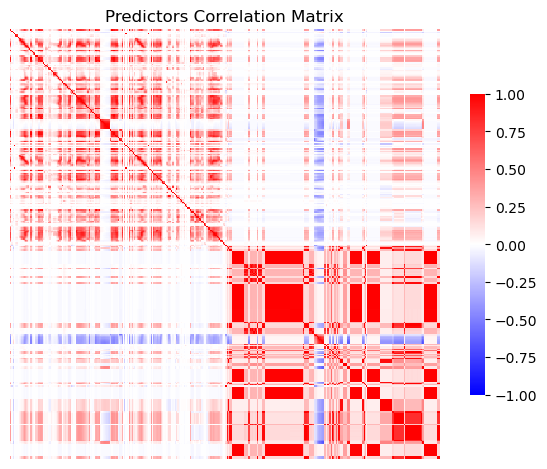

In [7]:
#1biii.) Correlation matrix for predictors

corr_matrix = X_train_imputed.corr(method='pearson', numeric_only=True)
sns.heatmap(corr_matrix, cmap="bwr", vmin=-1, vmax=1, center=0,
            xticklabels=False, yticklabels=False, 
            square=True, cbar_kws={"shrink": 0.7})
plt.title("Predictors Correlation Matrix")
plt.tight_layout()
plt.show()

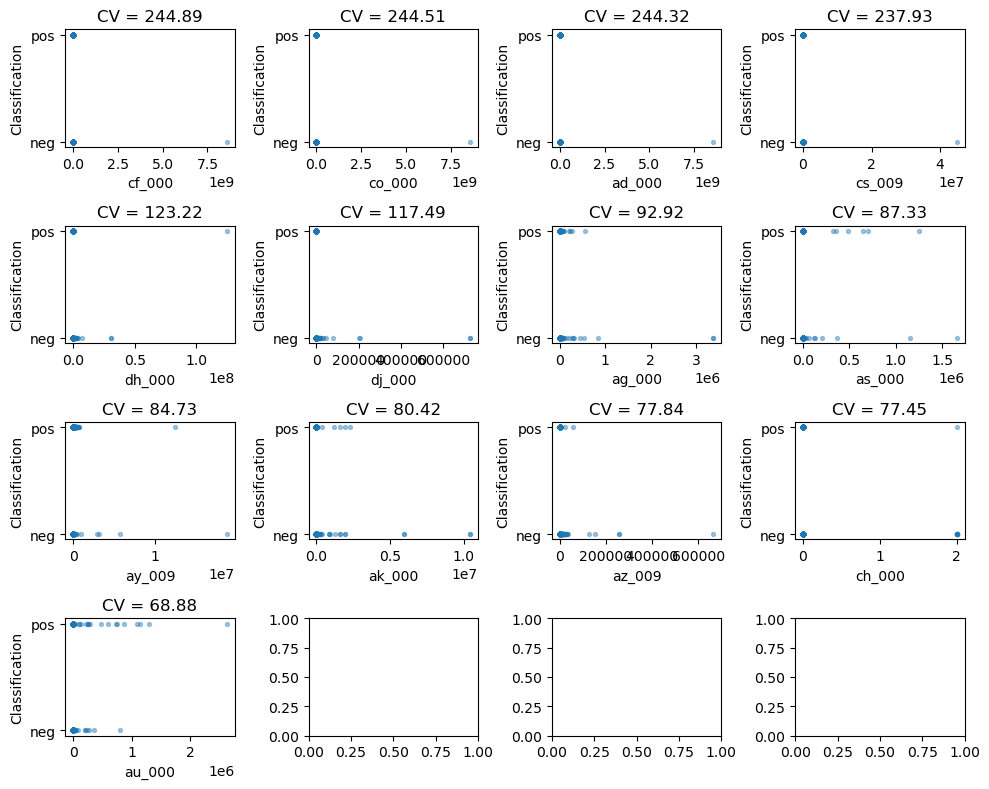

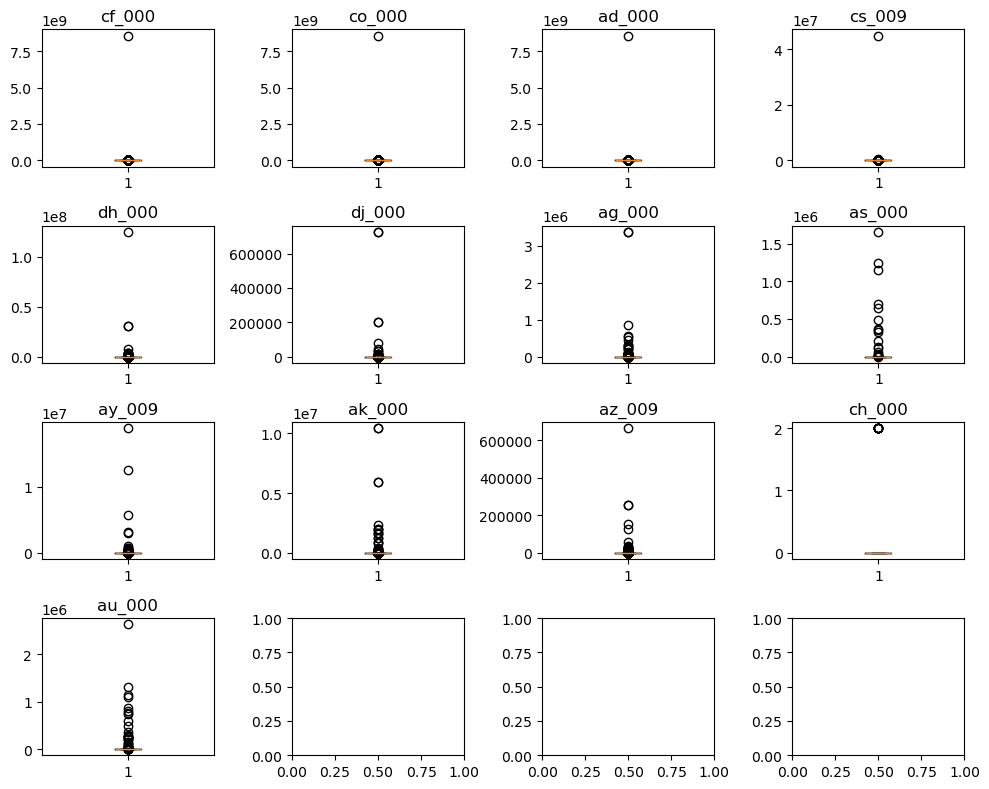

In [8]:
#1biv.) Scatter and Box Plots for sqrt of 170 with highest COV (top 13 predictors)

top_features = cv_results.sort_values(ascending=False).head(13).index

#Scatter Plots
fig, axes = plt.subplots(4, 4, figsize=(10,8))
axes = axes.ravel()

for ax, feat in zip(axes, top_features):
    ax.scatter(X_train_imputed[feat], y_train, s=8, alpha=0.4)
    ax.set_xlabel(feat)
    ax.set_ylabel("Classification")
    ax.set_title(f"CV = {cv_results[feat]:.2f}")

plt.tight_layout()
plt.show()

#Box Plots
fig, axes = plt.subplots(4, 4, figsize=(10,8))
axes = axes.ravel()

for ax, feat in zip(axes, top_features):
    ax.boxplot(X_train_imputed[feat].dropna(), vert=True)
    ax.set_title(feat)

plt.tight_layout()
plt.show()

In [9]:
#answer to iv.) 

In [10]:
#1bv.) Positive and Negative Data Inspection

y_train.value_counts()

#Answer: The dataset is imbalanced with the positive class being a minority class of 1000 observations out of 60,000, about 2%

class
neg    59000
pos     1000
Name: count, dtype: int64

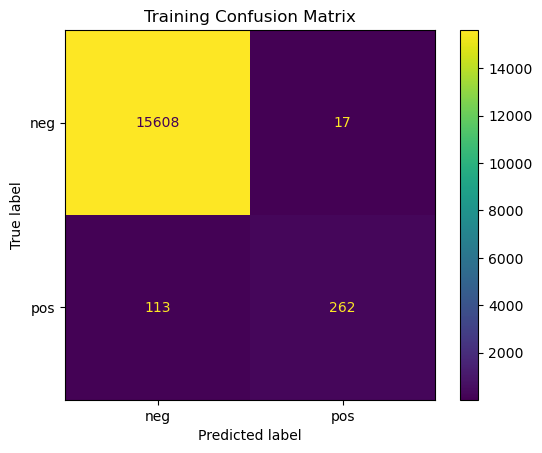

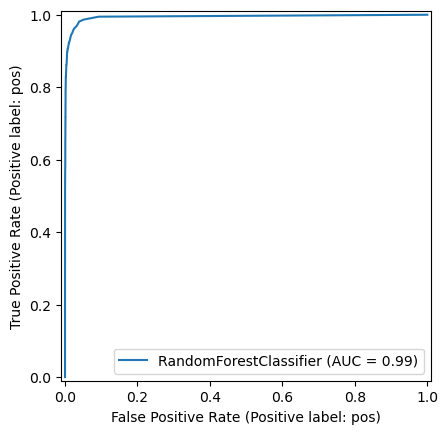

In [11]:
#1c.) Train a random forest classifier

rf = RandomForestClassifier(oob_score=True, random_state=42)
rf.fit(X_train_imputed, y_train)

y_pred = rf.predict(X_test_imputed)

#Probability Metric
y_prob = rf.predict_proba(X_test_imputed)[:,1] 

#Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay.from_estimator(rf, X_test_imputed, y_test) #visualize cf
plt.title("Training Confusion Matrix")
plt.show()

#ROC, AUC, and misclassification for training and testing set
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label='pos')
RocCurveDisplay.from_estimator(rf, X_test_imputed, y_test)


In [12]:
#1c.) OOB Error vs. Test Error

oob_accuracy = rf.oob_score_
oob_error = 1 - oob_accuracy

test_accuracy = accuracy_score(y_test, y_pred)
test_error = 1 - test_accuracy

print(f"OOB error is {oob_error:.4f} compared to test error which is {test_error:.4f}.")

OOB error is 0.0062 compared to test error which is 0.0081.


In [13]:
#1d. Using Class Weighting for correcting class imbalance in Random Forest Model

rf_weighted = clone(rf)
rf_weighted.set_params(class_weight='balanced')

rf_weighted.fit(X_train_imputed, y_train)

#Prediction with Class Weighting
y_pred = rf_weighted.predict(X_test_imputed)

#Probability Metric
y_prob = rf_weighted.predict_proba(X_test_imputed)[:,1] 

oob_accuracy_cw = rf_weighted.oob_score_
oob_error_cw = 1 - oob_accuracy_cw

test_accuracy_cw = accuracy_score(y_test, y_pred)
test_error_cw = 1 - test_accuracy_cw

print(f"OOB error is {oob_error_cw:.4f} compared to test error which is {test_error_cw:.4f} using class weighting to correct for class imbalance.")

OOB error is 0.0075 compared to test error which is 0.0104 using class weighting to correct for class imbalance.


In [15]:
#1e.) XGBoost and Model Trees

#Mapping numerically for XGboost
y_train_encoded = y_train.map({'neg': 0, 'pos': 1})
y_test_encoded = y_test.map({'neg': 0, 'pos': 1})

cross_val_score = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

alphas = [0, 0.01, 0.1, 1, 10]

for alpha in alphas:
    xgb_model = xgb.XGBClassifier(
        objective='binary:logistic',
        n_estimators=100,
        reg_alpha=alpha,
        random_state=42
    )

    pipeline = ImbPipeline([
        ('imputer', clone(imputer)),
        ('model', xgb_model)
    ])

    cv_scores = sklearn_cv_score(
        pipeline,
        X_train,
        y_train_encoded,
        cv=cv,
        scoring='accuracy'
    )

    cross_val_score[alpha] = 1 - cv_scores.mean()

best_alpha = min(cross_val_score, key=cross_val_score.get)

print(f"Best alpha: {best_alpha}")
print(f"CV misclassification error: {cross_val_score[best_alpha]:.4f}")

Best alpha: 0
CV misclassification error: 0.0064


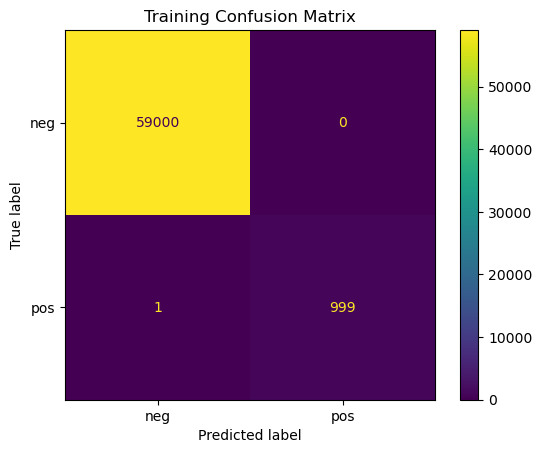

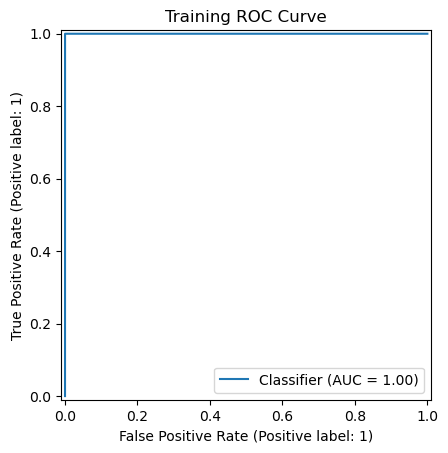

Training AUC: 1.0000
Training misclassification error: 0.0000


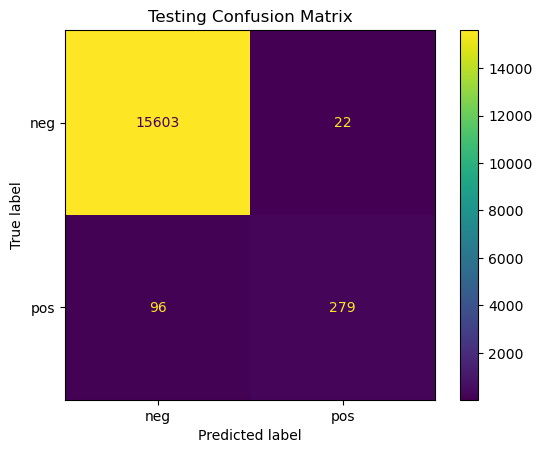

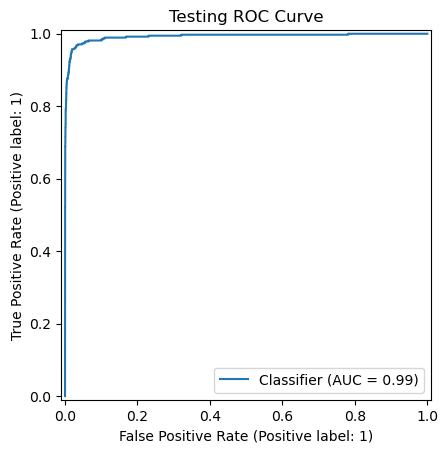

Testing AUC: 0.9926
Testing misclassification error: 0.0074
CV misclassification error: 0.0064


In [16]:
#1e.) Evaluation Metrics for XGBoost Model

chosen_model = ImbPipeline([
    ('imputer', clone(imputer)),
    ('model', xgb.XGBClassifier(
        objective='binary:logistic',
        n_estimators=100,
        reg_alpha=best_alpha,
        random_state=42
    ))
])

chosen_model.fit(X_train, y_train_encoded)

# Evaluate training and test data
for name, X, y in [
    ('Training', X_train, y_train_encoded),
    ('Testing', X_test, y_test_encoded)
]:
    y_pred = chosen_model.predict(X)
    y_prob = chosen_model.predict_proba(X)[:, 1]

    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y, y_pred,
        labels=[0, 1],
        display_labels=['neg', 'pos']
    )
    plt.title(f'{name} Confusion Matrix')
    plt.show()

    # ROC curve
    RocCurveDisplay.from_predictions(y, y_prob)
    plt.title(f'{name} ROC Curve')
    plt.show()

    # AUC and misclassification error
    auc = roc_auc_score(y, y_prob)
    error = 1 - accuracy_score(y, y_pred)

    print(f'{name} AUC: {auc:.4f}')
    print(f'{name} misclassification error: {error:.4f}')

print(f'CV misclassification error: {cross_val_score[best_alpha]:.4f}')

Best alpha: 0.1
CV misclassification error: 0.0061


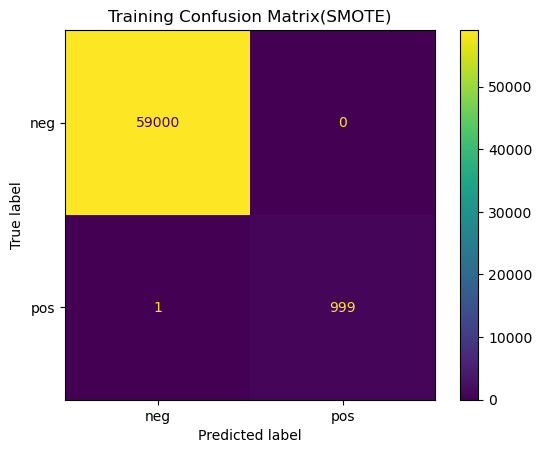

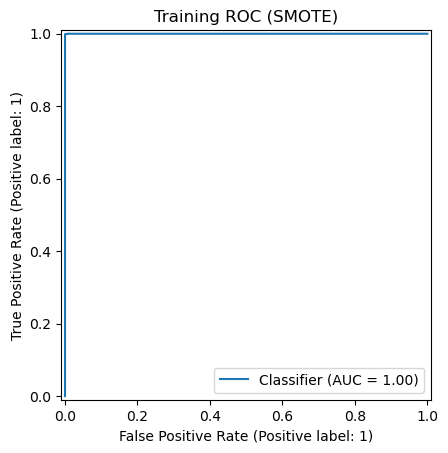

Training AUC: 1.0000
Training misclassification error: 0.0000


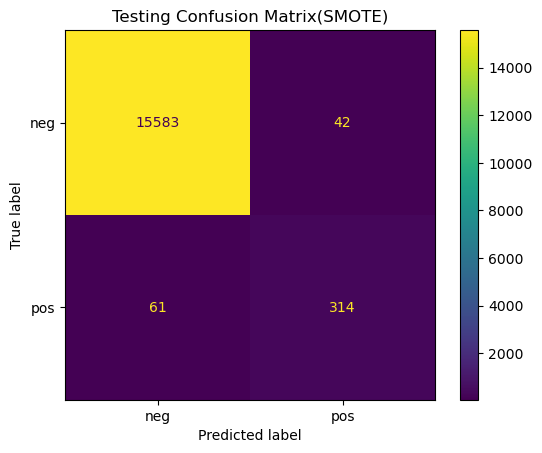

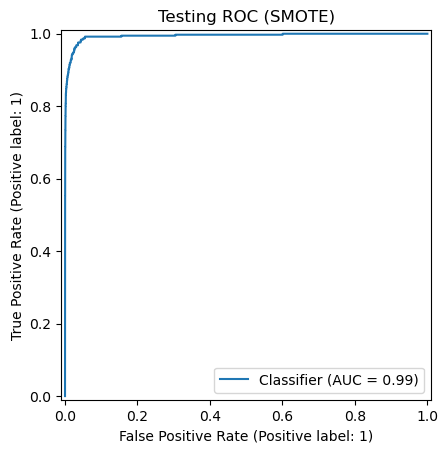

Testing AUC: 0.9942
Testing misclassification error: 0.0064


In [17]:
#1f Compensating for Class Imbalance and refitting Random Forest Model

pipeline_sm = ImbPipeline([
    ('imputer', clone(imputer)),
    ('smote', SMOTE(random_state=42)),
    ('model', clone(chosen_model.named_steps['model']))
])

# Apply SMOTE for training data folds in CV
search_sm = GridSearchCV(
    pipeline_sm,
    {'model__reg_alpha': alphas},
    scoring='accuracy',
    cv=cv
)

search_sm.fit(X_train, y_train_encoded)

# Refitting best pipeline
final_model_sm = search_sm.best_estimator_

print(f"Best alpha: {search_sm.best_params_['model__reg_alpha']}")
print(f"CV misclassification error: {1 - search_sm.best_score_:.4f}")

# Evaluate original training and test data
for name, X, y in [
    ('Training', X_train, y_train_encoded),
    ('Testing', X_test, y_test_encoded)
]:
    pred = final_model_sm.predict(X)
    prob =final_model_sm.predict_proba(X)[:, 1]

    ConfusionMatrixDisplay.from_predictions(
        y, pred,
        labels=[0, 1],
        display_labels=['neg', 'pos']
    )
    plt.title(f'{name} Confusion Matrix(SMOTE)')
    plt.show()

    RocCurveDisplay.from_predictions(y, prob)
    plt.title(f'{name} ROC (SMOTE)')
    plt.show()

    print(f'{name} AUC: {roc_auc_score(y, prob):.4f}')
    print(f'{name} misclassification error: '
          f'{1 - accuracy_score(y, pred):.4f}')

#ISLR 6.6.3

(a) iv. Steadily decrease  - a larger s value will always lower training RSS, reaching the least-squares fit at large s since thats the goal of the model.
(b) ii. Decrease initially, then increase in a U shape - test RSS improves as overfitting shrinks but then then worsens once the model overfits again.

(c) iii. Steadily increase - having a more flexible model has higher variance as s increases. 

(d) iv. Steadily decrease - a more flexible model fits the true nature of the data, which in turn causes bias to decrease.

(e) v. Remain constant: irreducible error (the variance of episolon) doesn’t have any impact from the model function, and is its own independnet value.

#ISLR 6.6.5


#ISLR 8.4.5


#ISLR 9.7.3.